In [ ]:
#Importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Begin to generate a random dataset with 1000 samples (rows) and 3 features (columns)
np.random.seed(42)
num_samples = 1000

In [ ]:
#Generate random scores between 0 and 100 for each subject
math_scores = np.random.randint(0, 101, num_samples)
science_scores = np.random.randint(0, 101, num_samples)
english_scores = np.random.randint(0, 101, num_samples)

In [ ]:
#Create a DataFrame to hold the scores
df = pd.DataFrame({'Math': math_scores, 'Science': science_scores, 'English': english_scores})

In [ ]:
#Display the first 5 rows of the DataFrame
df.head()

,Math,Science,English
0,51,56,62
1,92,16,85
2,14,85,1
3,71,89,87
4,60,43,71


In [ ]:
# Save the DataFrame to a CSV file
df.to_csv('student_performance.csv', index=False)

In [ ]:
# load the dataset from the CSV file
df = pd.read_csv('student_performance.csv')

df.head()

,Math,Science,English
0,51,56,62
1,92,16,85
2,14,85,1
3,71,89,87
4,60,43,71


In [ ]:
#Check for missing values in the dataset
missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)

Missing Values:
 Math       0
Science    0
English    0
dtype: int64


In [ ]:
df.dtypes

Math       int64
Science    int64
English    int64
dtype: object

In [ ]:
#Print a concise summary of the DataFrame, including the number of non-null entries and the data types of each column
print("DataFrame Info:")
print(df.info())

DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Math     1000 non-null   int64
 1   Science  1000 non-null   int64
 2   English  1000 non-null   int64
dtypes: int64(3)
memory usage: 23.6 KB
None


In [ ]:
#Print descriptive statistics for each subject, including count, mean, standard deviation, minimum, maximum, and quartiles
print("\nDescriptive Statistics:")
print(df.describe())


Descriptive Statistics:
              Math      Science      English
count  1000.000000  1000.000000  1000.000000
mean     49.937000    49.588000    48.117000
std      29.990072    29.547611    29.686067
min       0.000000     0.000000     0.000000
25%      23.000000    24.000000    21.750000
50%      50.000000    49.000000    46.000000
75%      76.000000    74.250000    74.250000
max     100.000000   100.000000   100.000000


In [ ]:
#Convert the DataFrame to a NumPy array
data_array = df.values
data_array[:5]  # Display the first 5 rows of the NumPy array

array([[51, 56, 62],
       [92, 16, 85],
       [14, 85,  1],
       [71, 89, 87],
       [60, 43, 71]])

In [ ]:
#Calculate various statistics for each subject
mean_scores = np.mean(data_array, axis=0)
max_scores = np.max(data_array, axis=0)
min_scores = np.min(data_array, axis=0)
standard_deviation_scores = np.std(data_array, axis=0)

median_scores = np.median(data_array, axis=0)
range_scores = np.ptp(data_array, axis=0)  # Peak-to-peak (max - min) range
variance_scores = np.var(data_array, axis=0)  # Variance
mode_scores = df.mode().iloc[0].values  # Mode (most frequent value)

correlation_matrix = np.corrcoef(data_array, rowvar=False)

#Print the calculated statistics
print("Mean Scores:", mean_scores)
print("Max Scores:", max_scores)
print("Min Scores:", min_scores)
print("Standard Deviation Scores:", standard_deviation_scores)
print("Median Scores:", median_scores)
print("Range Scores:", range_scores)
print("Variance Scores:", variance_scores)
print("Mode Scores:", mode_scores)
print("Correlation Matrix:\n", correlation_matrix)

Mean Scores: [49.937 49.588 48.117]
Max Scores: [100 100 100]
Min Scores: [0 0 0]
Standard Deviation Scores: [29.97507349 29.53283352 29.67122025]
Median Scores: [50. 49. 46.]
Range Scores: [100 100 100]
Variance Scores: [898.505031 872.188256 880.381311]
Mode Scores: [61. 28. 20.]
Correlation Matrix:
 [[ 1.         -0.04170913  0.05197945]
 [-0.04170913  1.         -0.03499334]
 [ 0.05197945 -0.03499334  1.        ]]


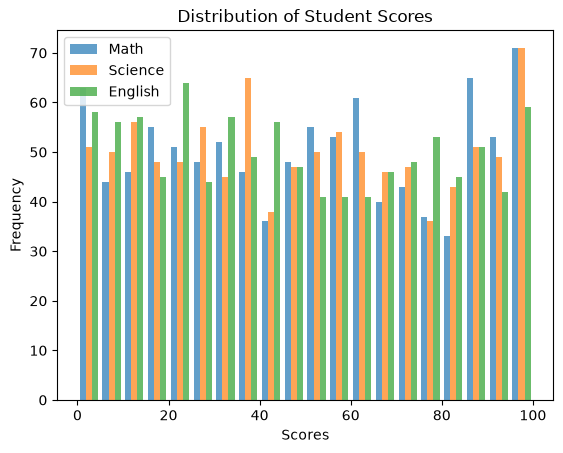

In [ ]:
#Plotting the distribution of scores for each subject using histograms
plt.hist(data_array, bins=20, alpha=0.7, label=['Math', 'Science', 'English'])
plt.title('Distribution of Student Scores')
plt.xlabel('Scores')
plt.ylabel('Frequency')
plt.legend()
plt.show()

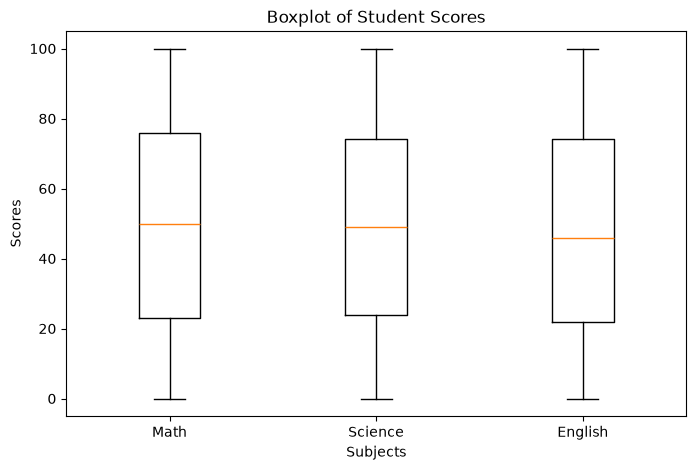

In [ ]:
#Plotting the distribution of scores for each subject using boxplots
plt.figure(figsize=(8, 5))
plt.boxplot(data_array, tick_labels=['Math', 'Science', 'English'])
plt.title('Boxplot of Student Scores')
plt.xlabel('Subjects')
plt.ylabel('Scores')
plt.show()

### Task 7: Interpretation

#### 1. Summary of Findings from Exploratory Data Analysis (EDA) and Visualisations
* **Central Tendency & Spread:** 
  * The dataset consists of 1,000 student samples across three core subjects: **Math, Science, and English**. 
  * The mean scores for each subject are remarkably close, hovering around **49.9 for Math, 49.6 for Science, and 48.1 for English**, with standard deviations around **29.5 to 30.0**. 
  * The median and mode values mirror this symmetry, with medians sitting right around 46 to 50.
* **Data Distributions (Histograms & Box Plots):** 
  * The histograms and box plots reveal a uniform distribution across all three subjects. 
  * Scores stretch evenly from a minimum of **0** to a maximum of **100**, with the interquartile range (IQR) spanning uniformly from roughly **22 to 75** and a median split right down the middle at **50**.
* **Correlations:** 
  * The correlation matrix coefficients between the subjects are all extremely close to zero (ranging between approximately **-0.04 and +0.05**), indicating **no linear relationship** or dependency between a student's performance in one subject versus another.

#### 2. Insights and Recommendations
* **Insights:** 
  * Because the data was synthetically generated using a uniform random distribution (`np.random.randint`), every possible score between 0 and 100 had an equal likelihood of occurring. 
  * The lack of correlation shows that student success in Math does not predict or influence success in Science or English, confirming that the variables operate independently.
* **Recommendations for Future Analysis:** 
  * **Real-World Data Application:** When transitioning from synthetic datasets to real-world educational data, expect to encounter skewed distributions (e.g., grade inflation or clustering around higher scores) and positive correlations (e.g., students who excel in one academic area often perform well across others due to general study habits).
  * **Feature Engineering / Grouping:** Consider introducing categorical variables (such as study hours, attendance rates, or socioeconomic factors) to build a predictive model that can find meaningful correlations and drive targeted student support interventions.
